# Lecture 25: Center and Spread
v.ekc

Two numbers summarize a distribution: the **average** (center) and the **standard deviation** (spread). Today: what they mean, Chebyshev's guarantee, and standard units, the common ruler for all datasets.

**Today's sections:**
1. The average
2. The standard deviation
3. Chebyshev's bounds
4. Standard units
5. The SD and bell curves

In [1]:
import matplotlib
from datascience import *
%matplotlib inline
import matplotlib.pyplot as plots
import numpy as np
plots.style.use('fivethirtyeight')

---
## 1. The Average (Mean)

Four values, five ways to compute the same mean, including as a **weighted sum of proportions**, which is why histograms are all you need.

In [2]:
values = make_array(2, 3, 3, 9)
values

array([2, 3, 3, 9])

Three built-ins that all say the same thing:

In [3]:
sum(values)/len(values)

4.25

In [4]:
np.average(values)

4.25

In [5]:
np.mean(values)

4.25

By hand now: straight arithmetic first, then the same mean as a weighted sum of proportions:

In [6]:
(2 + 3 + 3 + 9)/4

4.25

In [7]:
2*(1/4) + 3*(2/4) + 9*(1/4)

4.25

In [8]:
2*0.25 + 3*0.5 + 9*0.25

4.25

Put the values in a table and draw them:

In [9]:
values_table = Table().with_columns('value', values)
values_table

value
2
3
3
9


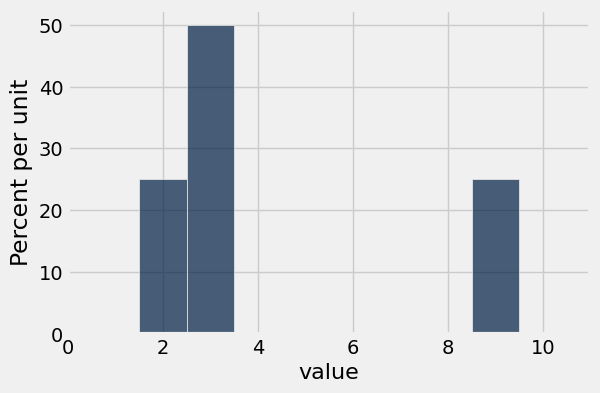

In [10]:
bins_for_display = np.arange(0.5, 10.6, 1)
values_table.hist('value', bins = bins_for_display)

Now 40 values with the *same proportions*, does the mean change??

In [11]:
## Make array of 10 2s, 20 3s, and 10 9s

new_vals = make_array(2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
                      3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
                      9, 9, 9, 9, 9, 9, 9, 9, 9, 9)

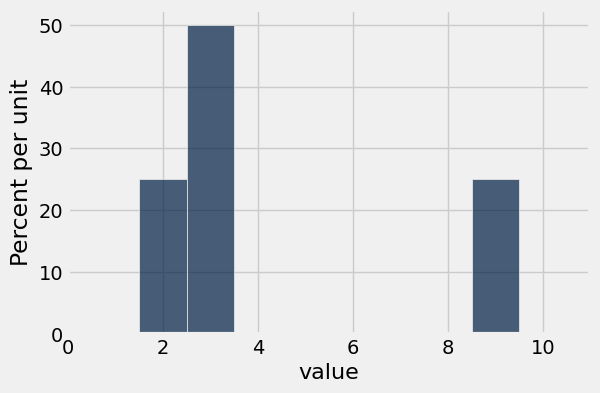

In [12]:
Table().with_column('value', new_vals).hist(bins = bins_for_display)

Same shape as before. Now compare the two means:

In [13]:
np.average(values)

4.25

In [14]:
np.average(new_vals)

4.25

Identical. And on the histogram, the mean is the balance point:

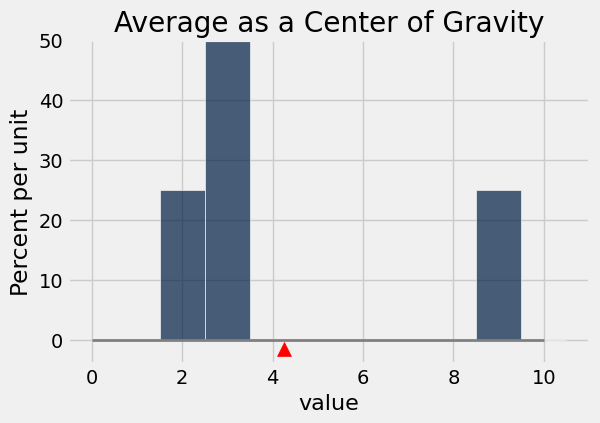

In [15]:
Table().with_column('value', new_vals).hist(bins = bins_for_display)
plots.ylim(-0.04, 0.5)
plots.plot([0, 10], [0, 0], color='grey', lw=2)
plots.scatter(4.25, -0.015, marker='^', color='red', s=100)
plots.title('Average as a Center of Gravity');

> **The mean depends only on the distribution**, same proportions, same mean, whether there are 4 values or 40. And on a histogram, the mean is the **balance point**; skewed tails drag it toward them (median resists; KL deck, slide 9).

### Try It 1: Mean, three ways 😊

1. With `w = make_array(1, 1, 5, 5)`, compute the mean with `np.average` and again as a **weighted sum of proportions**. Same answer?

2. Append one wild value, 100, to `w` (as a new array) and recompute the mean and the median (`percentile(50, ...)`). Which one moved more?

3. A town's average income jumps 40% the year one billionaire moves in. Which summary should the local paper report, and why?

In [16]:
# 1. mean of w, two ways


In [17]:
# 2. add 100, compare mean and median


*3. Your interpretation: (double-click to edit)*

<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*Proportions are all the mean needs, and one huge value drags it hard.*

```python
# 1.
w = make_array(1, 1, 5, 5)
np.average(w), 1*(2/4) + 5*(2/4)

# 2.
w_wild = np.append(w, 100)
np.average(w_wild), percentile(50, w_wild)   # mean 22.4, median 5
```

*3. The median. The mean chases the billionaire's tail; the median stays with the typical resident.*

</details>

---
## 2. The Standard Deviation

How far are values from the mean, *typically*? Build it in four steps:

### 📋 Reference Table

| Step | Code | Result |
|---|---|---|
| 1. deviations | `values - np.mean(values)` | they always sum to 0! |
| 2. square them | `deviations ** 2` | kills the canceling |
| 3. variance | `np.mean(deviations ** 2)` | mean squared deviation |
| 4. SD | `variance ** 0.5` or `np.std(values)` | back in the original units |

In [18]:
sd_table = Table().with_columns('Value', values)
sd_table

Value
2
3
3
9


In [19]:
average_value = np.mean(values)
average_value

4.25

In [20]:
deviations = values - average_value
sd_table = sd_table.with_column('Deviation', deviations)
sd_table

Value,Deviation
2,-2.25
3,-1.25
3,-1.25
9,4.75


Step 1 check: deviations always sum to zero, which is why we cannot just average them:

In [21]:
sum(deviations)

0.0

Step 2 squares away the canceling:

In [22]:
sd_table = sd_table.with_column('Squared Deviation', deviations ** 2)
sd_table

Value,Deviation,Squared Deviation
2,-2.25,5.0625
3,-1.25,1.5625
3,-1.25,1.5625
9,4.75,22.5625


Steps 3 and 4: the variance, then its square root to get back to the original units:

In [23]:
# Variance of the data:
# mean squared deviation from average

variance = np.mean(deviations ** 2)
variance

7.6875

In [24]:
# Standard Deviation (SD): 
# root mean squared deviation from average
# = square root of the variance

sd = variance ** 0.5
sd

2.7726341266023544

Or let numpy run all four steps at once:

In [25]:
np.std(values)

2.7726341266023544

### Try It 2: SD by hand 😊

1. Using the four steps (deviations, square, average, root), compute the SD of `new_vals` **without** `np.std`.

2. Check yourself with `np.std(new_vals)`.

3. Predict before you run: is the SD of `new_vals` bigger than, smaller than, or the same as the SD of `values`? Check, then explain.

In [26]:
# 1. four-step SD of new_vals


In [27]:
# 2. np.std check


In [28]:
# 3. predict, then compare with values


<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*Four steps in two lines, plus a callback to the 4-versus-40 trick.*

```python
# 1.
devs = new_vals - np.mean(new_vals)
np.mean(devs ** 2) ** 0.5

# 2.
np.std(new_vals)

# 3.
np.std(values), np.std(new_vals)   # identical!
```

*3. Same. Like the mean, the SD depends only on the distribution (the proportions), not on how many copies of it you stack up.*

</details>

---
## 3. Chebyshev's Bounds

**No matter the shape** of the distribution, *at least* 1 − 1/z² of the data lies within z SDs of the mean: *at least* 75% within 2 SDs, *at least* 88.9% within 3.

Let's check on the maternal data, and note the observed proportions are usually much *higher* than the guarantee:

In [29]:
births = Table.read_table('baby.csv').drop('Maternal Smoker')

In [30]:
births.labels

('Birth Weight',
 'Gestational Days',
 'Maternal Age',
 'Maternal Height',
 'Maternal Pregnancy Weight')

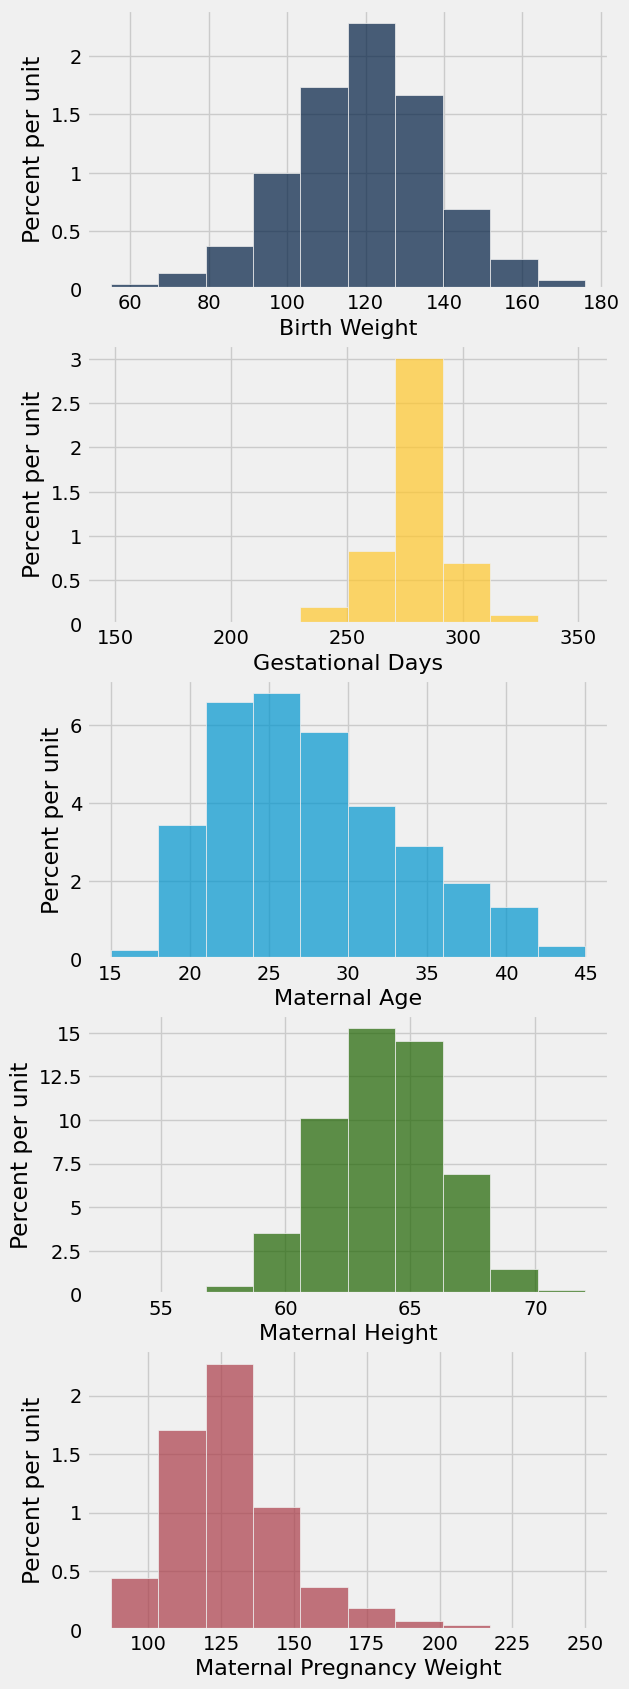

In [31]:
births.hist(overlay = False)

Focus on pregnancy weight: mean and SD first:

In [32]:
mpw = births.column('Maternal Pregnancy Weight')
mean = np.mean(mpw)
sd = np.std(mpw)
mean, sd

(128.4787052810903, 20.725449704280411)

Count the rows within 3 SDs of the mean:

In [33]:
within_3_SDs = births.where(
    'Maternal Pregnancy Weight', are.between(mean - 3*sd, mean + 3*sd))

In [34]:
# Proportion within 3 SDs of the mean

within_3_SDs.num_rows / births.num_rows

0.9863713798977853

Chebyshev only promised at least this much:

In [35]:
# Chebyshev's bound: 
# This proportion should be at least

1 - 1/3**2

0.8888888888888888

Now sweep every column and several z values to see if Chebychev works for every distribution we have!!!

In [36]:
births.labels

('Birth Weight',
 'Gestational Days',
 'Maternal Age',
 'Maternal Height',
 'Maternal Pregnancy Weight')

In [37]:
# See if Chebyshev's bounds work for distributions with various shapes

for feature in births.labels:
    values = births.column(feature)
    mean = np.mean(values)
    sd = np.std(values)
    print()
    print(feature)
    for z in make_array(2, 3, 4, 5):
        chosen = births.where(feature, are.between(mean - z*sd, mean + z*sd))
        proportion = chosen.num_rows / births.num_rows
        percent = round(proportion * 100, 2)
        print('Average plus or minus', z, 'SDs:', percent, '%')


Birth Weight
Average plus or minus 2 SDs: 94.89 %
Average plus or minus 3 SDs: 99.57 %
Average plus or minus 4 SDs: 100.0 %
Average plus or minus 5 SDs: 100.0 %

Gestational Days
Average plus or minus 2 SDs: 93.78 %
Average plus or minus 3 SDs: 98.64 %
Average plus or minus 4 SDs: 99.57 %
Average plus or minus 5 SDs: 99.83 %

Maternal Age
Average plus or minus 2 SDs: 94.89 %
Average plus or minus 3 SDs: 99.91 %
Average plus or minus 4 SDs: 100.0 %
Average plus or minus 5 SDs: 100.0 %

Maternal Height
Average plus or minus 2 SDs: 97.19 %
Average plus or minus 3 SDs: 99.66 %
Average plus or minus 4 SDs: 99.91 %
Average plus or minus 5 SDs: 100.0 %

Maternal Pregnancy Weight
Average plus or minus 2 SDs: 95.06 %
Average plus or minus 3 SDs: 98.64 %
Average plus or minus 4 SDs: 99.49 %
Average plus or minus 5 SDs: 99.91 %


### Try It 3: Your own Chebyshev check

1. For `Birth Weight`: what **proportion** of babies are within 2 SDs of the mean birth weight?

2. What does Chebyshev guarantee for 2 SDs? Does your observed proportion clear the bar?

In [38]:
# 1. proportion within 2 SDs


In [39]:
# 2. the Chebyshev bound for z = 2


<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*Same steps as the 3-SD demo: but use a new column, new z.*

```python
# 1.
bw = births.column('Birth Weight')
bw_mean = np.mean(bw)
bw_sd = np.std(bw)
births.where('Birth Weight', are.between(bw_mean - 2*bw_sd, bw_mean + 2*bw_sd)).num_rows / births.num_rows

# 2.
1 - 1/2**2
```

*2. The guarantee is at least 75%; the observed share is about 95%, comfortably above it. Chebyshev is a floor, not a solid predictor value.*

</details>

---
## 4. Standard Units

`(x − mean) / SD`: how many SDs above (+) or below (−) the mean. Every dataset converted to standard units has mean 0 and SD 1, one ruler for everything.

In [40]:
def standard_units(x):
    """Convert array x to standard units."""
    return (x - np.mean(x)) / np.std(x)

In [41]:
ages = births.column('Maternal Age')
ages

array([27, 33, 28, ..., 30, 21, 38])

Convert, then check the mean and SD of the result:

In [42]:
ages_standard_units = standard_units(ages)
ages_standard_units

array([-0.03925456,  0.99249577,  0.13270383, ...,  0.47662061,
       -1.07100488,  1.85228771])

In [43]:
np.mean(ages_standard_units), np.std(ages_standard_units)


(-7.868020072300939e-17, 1.0)

In [44]:
both = Table().with_columns(
    'Age in Years', ages,
    'Age in Standard Units', ages_standard_units
)
both

Age in Years,Age in Standard Units
27,-0.0392546
33,0.992496
28,0.132704
23,-0.727088
25,-0.383171
33,0.992496
23,-0.727088
25,-0.383171
30,0.476621
27,-0.0392546


In [45]:
np.mean(ages), np.std(ages)

(27.228279386712096, 5.8153604041908968)

Two histograms of the same data; only the ruler changes:

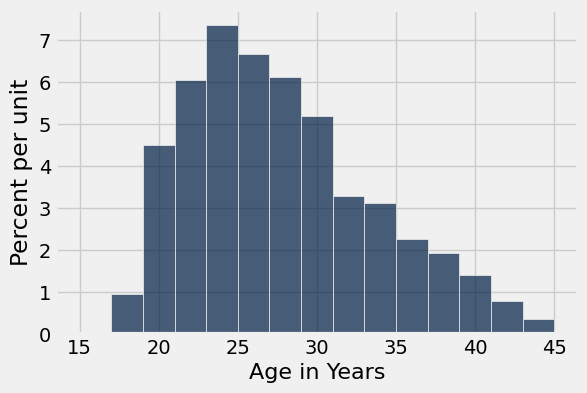

In [46]:
both.hist('Age in Years', bins = np.arange(15, 46, 2))

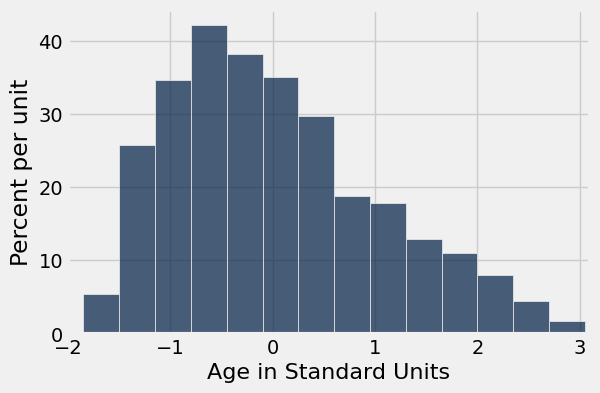

In [47]:
both.hist('Age in Standard Units', bins = np.arange(-2.2, 3.4, 0.35))
plots.xlim(-2, 3.1);

> **Same histogram, new axis:** converting to standard units doesn't change the shape at all, only the units :)

### Try It 4: Who is more unusual? 😊

1. In standard units, where does a **250-pound** pregnancy weight fall? (Use the mean and SD of `Maternal Pregnancy Weight`.)

2. In standard units, where does a **45-year-old** mother fall?

3. Which of the two is more extreme, and how do standard units make that comparison fair?

In [48]:
# 1. 250 lb in standard units


In [49]:
# 2. 45 years in standard units


*3. Your interpretation: (double-click to edit)*

<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*For a single value, standard units is just (value - mean) / SD.*

```python
# 1.
wt = births.column('Maternal Pregnancy Weight')
(250 - np.mean(wt)) / np.std(wt)   # about +5.9

# 2.
(45 - np.mean(ages)) / np.std(ages)   # about +3.1
```

*3. The 250-pound weight, at nearly 6 SDs, is far more extreme than the 45-year-old at about 3. Standard units measure each value against its own distribution, so pounds and years can go head to head.*

</details>

---
## 5. The SD and Bell Curves 🔔

On a bell-shaped histogram you can *see* the SD: it's the distance from the mean to the **point of inflection** (where the curve switches from bulging out to bending in).

### Try It 5: Estimate by eye 👀

1. From the histogram below: the average is approximately…?

2. Locate the point of inflection on the right, the SD is approximately…? Then check both with code.

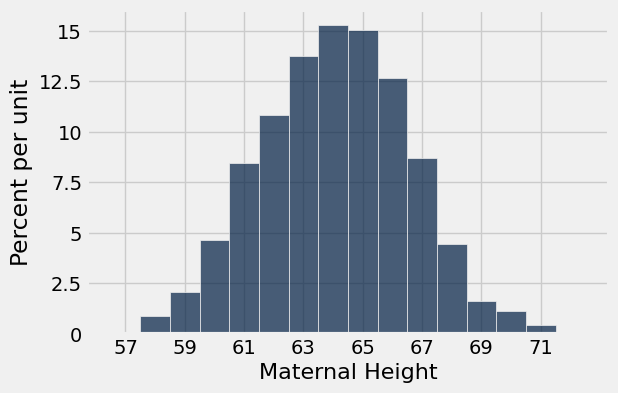

In [50]:
births.hist('Maternal Height', bins = np.arange(56.5, 72.6, 1))
plots.xticks(np.arange(57, 72, 2));

In [51]:
# 1–2. your eye-estimates, then check with np.mean / np.std


<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*Eyeball: mean ≈ 64 inches, inflection ≈ 66.5 → SD ≈ 2.5. The check:*

```python
heights = births.column('Maternal Height')
np.mean(heights), np.std(heights)     # (64.05, 2.52)
```

</details>

In [52]:
heights = births.column('Maternal Height')
np.mean(heights), np.std(heights)

(64.049403747870528, 2.5250254409674375)

---
> **Today's takeaway:** mean = balance point, SD = typical distance from it, Chebyshev guarantees most data is within a few SDs *no matter what*, and standard units make every dataset comparable. Next: the one curve where the SD tells you everything.

## Appendix — Quick Reference

Full `datascience` docs: [data8.org/datascience](https://data8.org/datascience/)

### Minimal template — standard units
```python
def standard_units(x):
    return (x - np.mean(x)) / np.std(x)
```